## DiffGSP tutorial 4: mouse kidney Stereo-seq dataset

The data used in this tutorial can be downloaded from [STOmicsDB](https://db.cngb.org/stomics/datasets/STDS0000240/data) and processed into h5ad format.

In [1]:
import DiffGSP as dg
import torch
import os
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')

### 1. Define input and output paths

In [3]:
data_dir = Path("/home/liujixin/datasets/Stereoseq/Mouse_Kidney")
res_dir = Path("/home/liujixin/project/DiffGSP/results/Stereoseq")
data_name = 'mouse_kidney_A02497C1'
res_dir = res_dir / data_name
if not res_dir.exists():
    res_dir.mkdir(parents=True)


### 2. Load and preprocess the data

Genes detected in fewer than 10 spots are removed. The top 2,000 spatially variable genes are then selected using the SpaGFT-based SVG selection implemented in DiffGSP.

In [4]:
bin = 50
adata = sc.read_h5ad(data_dir / "h5ad" / f"{data_name}_{bin}.h5ad")
adata.obs['in_tissue'] = 1
dg.seed_all(42)

# prefilter
adata.var['mt'] = adata.var_names.str.startswith(('mt-', 'MT-'))
adata = adata[:, ~adata.var['mt']]
adata = adata[:, dg.prefilter_genes(adata, min_cells=10)]
svgs = dg.select_svgs(adata, svg_method='gft_top', n_top=2000, boost=True)
adata = adata[:, svgs]

Number of down-sampled spots: 1116


### 3. Save the preprocessed original data


In [5]:
# save original gene expression profiles
adata_orig = adata.copy()
adata_orig.write_h5ad(res_dir / f"{data_name}_Original.h5ad")

### 4. Run DiffGSP

Here, we run DiffGSP on the mouse brain Slide-seqV2 data. Since this dataset does not contain out-of-tissue spots for parameter estimation, we choose to define parameters according to data.

variable: parameters for inverse diffusion and smoothing. In this example, variable=[0.1, 0.01] means the inverse diffusion parameter is 0.1 and the smoothing parameter is 0.01.

You can adjust the inverse diffusion parameters to increase the degree of diffusion correction, for example by increasing the first element of `variable` and/or increasing `k`. Note that, to avoid unstable solutions, the diffusion parameter will be dynamically adjusted unless you set `inv=False`.

In [6]:
dg.seed_all(42)
# reload the preprocessed data to ensure a clean start
adata = sc.read_h5ad(res_dir / f"{data_name}_Original.h5ad")

k = 5
adata, _, _, _ = dg.run_diffgsp(adata,
                                gene_network=False,
                                k=k,
                                device=device,
                                method='manual',
                                variable=[0.1, 0.01],
                                data_type='Stereoseq',
                                inv_cutoff='auto')

# save result without inv suffix
adata.write_h5ad(res_dir / f"{data_name}_DiffGSP.h5ad")

New para 0.10279595897092304
Current parameters: 	 [np.float64(0.10279595897092304), 0.01]


### 5. Visualize selected marker genes

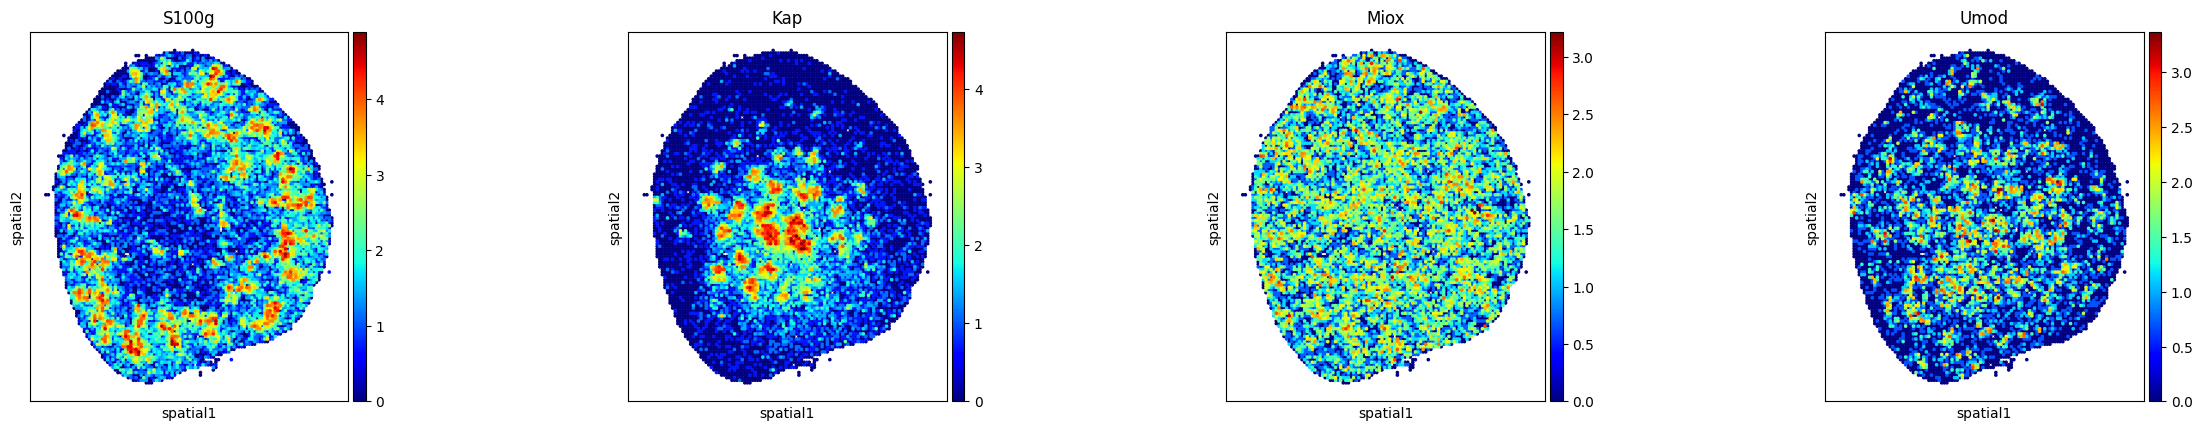

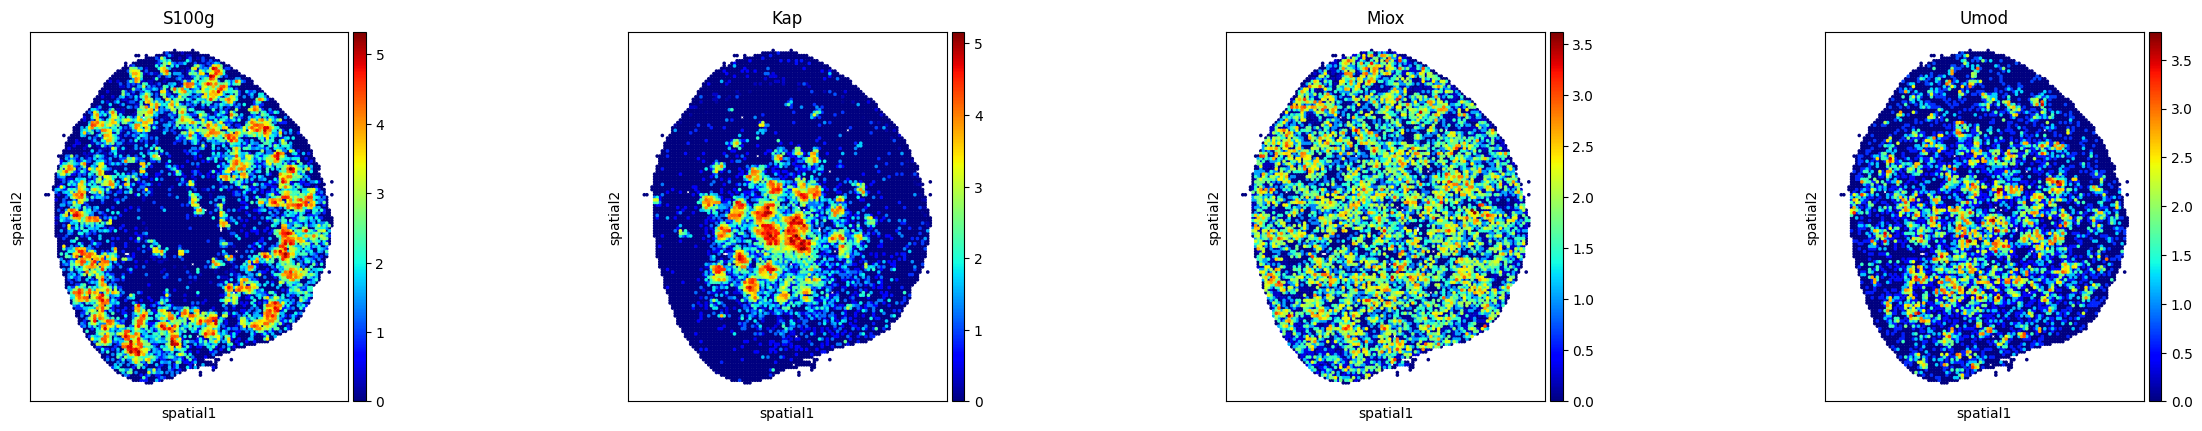

In [8]:
# Load original data and DiffGSP result
adata_orig = sc.read_h5ad(res_dir / (data_name + "_Original.h5ad"))
adata_diff = sc.read_h5ad(res_dir / (data_name + "_DiffGSP.h5ad"))
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)

# Marker genes to visualize
selected_genes = ['S100g', 'Kap', 'Miox', 'Umod']

# Plot spatial expression in the original data
sc.pl.spatial(adata_orig,
              color=selected_genes,
              cmap='jet',
              spot_size=70)

# Plot spatial expression in the DiffGSP result
sc.pl.spatial(adata_diff,
              color=selected_genes,
              cmap='jet',
              spot_size=70)